## Lab -3-

**Exploratory Data Analysis (EDA) and Leakage-Safe Preprocessing for the Titanic Dataset**

## Learning Objectives

By the end of this lab, you will be able to:

1. **Profile** a tabular dataset by inspecting schema, data types, ranges, missingness, duplicates, and summary statistics.
2. **Interpret** descriptive statistics, skewness, kurtosis, correlations, and visual patterns to explain data quality and structure.
3. **Detect** anomalies using visualization, IQR-based rules, and z-score style reasoning, then justify whether to remove, transform, or flag them.
4. **Implement** categorical, binary, and numerical feature transformations, including target label encoding, one-hot encoding, and numerical scaling.
5. **Validate** a leakage-safe preprocessing workflow with `Pipeline` and `ColumnTransformer`.
6. **Compare** a baseline model and an improved model using reproducible train/test evaluation.
7. **Diagnose** limitations of EDA choices and propose monitoring signals for production ML systems.

## Tasks

- Load Titanic training and competition test data from public URLs and verify schema.
- Build a compact profiling table for data types, missingness, cardinality, and duplicates.
- Compute descriptive statistics and inspect skewness, kurtosis, and class imbalance.
- Visualize distributions with histograms, bar charts, boxplots, scatterplots, and a correlation heatmap.
- Investigate missing values and reason about likely missingness mechanisms.
- Detect anomalies in `Fare` and `Age`, then decide whether to remove, cap, transform, or flag them.
- Encode the target label with `LabelEncoder`, and compare binary/numerical encoding with one-hot encoding for features.
- Apply `log1p` and scaling to skewed numerical features.
- Build a reproducible baseline logistic-regression model.
- Build an improved leakage-safe preprocessing pipeline and compare results.

**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.

## References

### Official Documentation

- [pandas.read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
- [pandas.DataFrame.describe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
- [pandas.get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)
- [matplotlib.pyplot.hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)
- [matplotlib.pyplot.boxplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html)
- [sklearn.preprocessing.LabelEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html)
- [sklearn.preprocessing.OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [sklearn.compose.ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [sklearn.pipeline.Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [sklearn.impute.SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)
- [sklearn.model_selection.train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
- [sklearn.linear_model.LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

###  References

- [Kaggle Titanic competition overview](https://www.kaggle.com/competitions/titanic)
- [Scikit-learn mixed-type preprocessing example](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)

### Python Commands and Quick Reference

- Load data: `pd.read_csv(...)`
- Inspect schema: `df.info()`, `df.dtypes`, `df.head()`, `df.sample()`
- Missingness: `df.isna().sum()`, `df.isna().mean()`
- Descriptive stats: `df.describe()`, `series.skew()`, `series.kurt()`
- Duplicates: `df.duplicated().sum()`
- Encoding: `LabelEncoder()`, `pd.get_dummies(...)`, `OneHotEncoder(...)`
- Scaling/transform: `np.log1p(...)`, `StandardScaler()`, `MinMaxScaler()`
- Splitting: `train_test_split(...)`
- Pipelines: `Pipeline(...)`, `ColumnTransformer(...)`
- Evaluation: `accuracy_score(...)`, `roc_auc_score(...)`, `classification_report(...)`

## A Typical Data Exploration Workflow

1. Setup and reproducibility  
2. Data acquisition  
3. Data validation and schema checks  
4. Descriptive statistics and first-pass profiling  
5. Missingness analysis  
6. Univariate visual analysis  
7. Bivariate and multivariate visual analysis  
8. Outlier and anomaly detection  
9. Categorical and label encoding  
10. Numerical transformation and scaling  
11. Train/test split and baseline model  
12. Leakage-safe preprocessing pipeline and improved model  
13. Diagnostics and interpretation  
14. ML systems discussion: reproducibility, leakage, monitoring, and drift

## Dataset

**Dataset name:** Titanic — Machine Learning from Disaster

**Primary links**

- Competition page: https://www.kaggle.com/competitions/titanic
- Public training CSV mirror: `https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv`
- Public competition test CSV mirror: `https://raw.githubusercontent.com/dsindy/kaggle-titanic/master/data/test.csv`

**Usage note**
- The Titanic dataset is suitable for classification and notes that the classes are ordered and imbalanced.

**Brief description**

The dataset contains passenger-level information such as survival outcome, passenger class, sex, age, number of siblings/spouses aboard, number of parents/children aboard, fare, cabin, and embarkation port. The competition training set includes the target `Survived`; the competition test set omits `Survived` and is useful for schema comparison and production-style inference.


## Lab Instructions 

| Step | Action |
|---|---|
| 1 | Configure imports, plotting defaults, display options, and random seeds. |
| 2 | Load Titanic train/test CSV files and document dataset metadata. |
| 3 | Validate schema, data types, label presence, duplicates, and column-level missingness. |
| 4 | Compute descriptive statistics and summarize skewness, kurtosis, and class balance. |
| 5 | Visualize univariate distributions for `Age`, `Fare`, `Pclass`, `Sex`, and `Embarked`. |
| 6 | Visualize survival relationships with bar plots, grouped summaries, boxplots, and a correlation heatmap. |
| 7 | Detect anomalies with IQR bounds, z-score reasoning, and targeted scatter plots. |
| 8 | Transform the label and categorical predictors using label encoding, binary encoding, and one-hot encoding. |
| 9 | Apply numerical transformations such as `log1p` and scaling; assemble preprocessing pipelines. |
| 10 | Train a baseline logistic-regression model and evaluate reproducibly. |
| 11 | Train an improved leakage-safe model with `ColumnTransformer` and compare diagnostics. |
| 12 | Reflect on limitations, monitoring, drift, reliability, and deployment considerations. |

### Step 1 — Setup & Reproducibility

### Pre-coding questions

1. Which parts of this notebook are most sensitive to randomness, and which parts should be deterministic?  
The train/test split and model training can be sensitive to randomness. Using a fixed random_state makes these steps reproducible.

2. Why is a fixed `random_state` necessary but not sufficient for exact reproducibility across machines?    
A fixed random_state helps produce the same random split and random operations, but differences in Python versions, package versions, operating systems, hardware, and numerical libraries can still cause slightly different results.

3. What experiment metadata should be logged before model fitting begins?   
I would log the dataset source, dataset version or date, Python version, package versions, random seed, feature list, preprocessing steps, train/test split size, model type, model parameters, and evaluation metrics.

### Function/class selection and parameter exploration

Use:

- `numpy.random.seed`
- `pandas.set_option`
- `matplotlib.pyplot.rcParams`
- `sklearn.model_selection.train_test_split`

Explore with `help()` or notebook `?`:

- `train_test_split(test_size, random_state, shuffle, stratify)`

Explain the effect of:

- `random_state` on reproducibility
- `test_size` on bias/variance of evaluation
- `shuffle` on row-order sensitivity
- `stratify` on label balance and evaluation validity

In [1]:
# Step 1: Setup & reproducibility
import platform
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Random state:", RANDOM_STATE)

Python: 3.13.9
pandas: 2.3.3
NumPy: 2.3.5
Random state: 42


### Post-execution interpretation questions

1. Which printed details are essential for reproducibility auditing later?  
The Python version, pandas version, NumPy version, and random state are important. The dataset source and other package versions should also be recorded even though they are not all printed in this cell.

2. Why should the seed be declared near the top of the notebook instead of only inside the modeling cell?   
The seed should be near the top so that every random operation throughout the notebook can use the same reproducible setting. This also makes the notebook easier to audit and reproduce.

3. Limitation question: what reproducibility issue remains even if all students use the same seed?  
Students can still get different results if they use different versions of Python, pandas, NumPy, scikit-learn, or other libraries. Changes in the dataset or operating system can also affect results.

 
4. **Think like an ML Systems engineer:** what would you store in an experiment log to debug unexpected score changes next semester?    
I would store the dataset version, dataset URL, date of the experiment, Python version, package versions, random seed, feature list, preprocessing steps, model settings, train/test split, and evaluation results. I would also save the trained model and code version if possible.

### Step 2 — Data Acquisition

### Pre-coding questions

1. Why is it useful to load both the competition training set and the competition test set even though only the training set contains labels?   
Loading both datasets allows us to compare their schemas and make sure that the features available during training are also available during inference. It also gives us an example of how a real production dataset may not contain the target variable.

2. What failure mode could occur if the training and production-time schemas drift apart?   
The model could receive missing columns, unexpected columns, different data types, or new categorical values. This could cause errors or produce unreliable predictions.

3. Why might a public mirror be useful in a teaching notebook even when the original source is Kaggle?  
A public mirror can make the dataset easier to access without requiring students to download files manually or configure a Kaggle API. It also makes the notebook easier to reproduce.

### Function/class selection and parameter exploration

Use:

- `pandas.read_csv`
- `pandas.DataFrame.shape`
- `pandas.DataFrame.head`

Explore with `help()` or notebook `?`:

- `pd.read_csv(filepath_or_buffer, usecols=None, dtype=None, na_values=None)`

Explain the effect of:

- `usecols` on memory and load speed
- `dtype` on type stability
- `na_values` on missing-value parsing
- remote URLs on reproducibility and classroom accessibility

In [2]:
# Step 2A: Load Titanic datasets
TRAIN_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
TEST_URL = "https://raw.githubusercontent.com/dsindy/kaggle-titanic/master/data/test.csv"

train_df = pd.read_csv(TRAIN_URL)
test_df = pd.read_csv(TEST_URL)

display(train_df.head())
display(test_df.head())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.500,0,0,330911,7.829,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.000,1,0,363272,7.000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.000,0,0,240276,9.688,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.000,0,0,315154,8.662,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.000,1,1,3101298,12.287,NaN,S


Train shape: (891, 12)
Test shape: (418, 11)


In [3]:
dataset_metadata = {
    "dataset_name": "Titanic - Machine Learning from Disaster",
    "train_rows": int(train_df.shape[0]),
    "train_columns": int(train_df.shape[1]),
    "test_rows": int(test_df.shape[0]),
    "test_columns": int(test_df.shape[1]),
    "target_name": "Survived",
    "source_urls": {
        "train": TRAIN_URL,
        "test": TEST_URL
    }
}
dataset_metadata

{'dataset_name': 'Titanic - Machine Learning from Disaster',
 'train_rows': 891,
 'train_columns': 12,
 'test_rows': 418,
 'test_columns': 11,
 'target_name': 'Survived',
 'source_urls': {'train': 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv',
  'test': 'https://raw.githubusercontent.com/dsindy/kaggle-titanic/master/data/test.csv'}}

In [4]:
assert "Survived" in train_df.columns
assert "Survived" not in test_df.columns

shared_feature_columns = sorted(set(test_df.columns).intersection(set(train_df.columns)))
assert set(shared_feature_columns) == set(train_df.columns) - {"Survived"}

shared_feature_columns[:5], len(shared_feature_columns)

(['Age', 'Cabin', 'Embarked', 'Fare', 'Name'], 11)

### Post-execution interpretation questions

1. Why is the absence of `Survived` in the competition test set expected rather than a data-quality problem?    
Survived is the target that the model is supposed to predict. The competition test set does not provide the target because the model is expected to generate predictions for those passengers.

2. What schema issue would be more serious than a simple difference in row count?   
Missing or incorrectly named feature columns would be more serious. Different data types or unexpected categorical values could also cause problems during model inference.


3. **Think like an ML Systems engineer:** 
   -If a new production batch introduces a new categorical value in `Embarked`, what could happen without defensive preprocessing?  
   The model could fail because it has not seen the new category before. Using OneHotEncoder(handle_unknown="ignore") allows the model to handle an unseen category without crashing.

### Step 3 — Data Validation & First-Pass Profiling

### Pre-coding questions

1. Which columns do you expect to have substantial missingness, and why?    
Cabin is expected to have substantial missingness because cabin information was not recorded for many passengers. Age also has missing values because the ages of some passengers were unknown. Embarked has only a small number of missing values.

2. Why can a column with many unique values still be a poor modeling feature?   
A column can have many unique values but still have little predictive value. For example, Name contains many unique values and could create a very large number of categories without providing a simple and reliable relationship to survival.

3. Why should duplicate checks happen before modeling and not after?    
Duplicate records can cause certain observations to receive too much influence during training. Checking duplicates before modeling helps ensure that the dataset accurately represents the observations being studied.

### Function/class selection and parameter exploration

Use:

- `DataFrame.dtypes`
- `DataFrame.isna`
- `DataFrame.nunique`
- `DataFrame.duplicated`

Explore with `help()` or notebook `?`:

- `DataFrame.isna()`
- `DataFrame.nunique(dropna=True)`
- `DataFrame.duplicated(subset=None, keep='first')`

Explain the effect of:

- `dropna` when computing cardinality
- `subset` in duplicate detection
- datatype inference on downstream preprocessing

In [5]:
# Step 3A: Compact profiling table
def profile_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    profile = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_rate": df.isna().mean(),
        "n_unique": df.nunique(dropna=True)
    })
    profile["sample_value"] = [df[col].dropna().iloc[0] if df[col].dropna().shape[0] > 0 else np.nan for col in df.columns]
    return profile.sort_values(["missing_rate", "n_unique"], ascending=[False, False])

train_profile = profile_dataframe(train_df)
display(train_profile)

,dtype,missing_count,missing_rate,n_unique,sample_value
Cabin,object,687,0.771,147,C85
Age,float64,177,0.199,88,22.000
Embarked,object,2,0.002,3,S
PassengerId,int64,0,0.000,891,1
Name,object,0,0.000,891,"Braund, Mr. Owen Harris"
Ticket,object,0,0.000,681,A/5 21171
Fare,float64,0,0.000,248,7.250
SibSp,int64,0,0.000,7,1
Parch,int64,0,0.000,7,0
Pclass,int64,0,0.000,3,3


In [6]:
validation_summary = pd.DataFrame({
    "check": [
        "total_rows",
        "total_columns",
        "duplicate_rows",
        "duplicate_passenger_ids",
        "missing_target_labels"
    ],
    "value": [
        int(train_df.shape[0]),
        int(train_df.shape[1]),
        int(train_df.duplicated().sum()),
        int(train_df["PassengerId"].duplicated().sum()),
        int(train_df["Survived"].isna().sum())
    ]
})
display(validation_summary)

,check,value
0,total_rows,891
1,total_columns,12
2,duplicate_rows,0
3,duplicate_passenger_ids,0
4,missing_target_labels,0


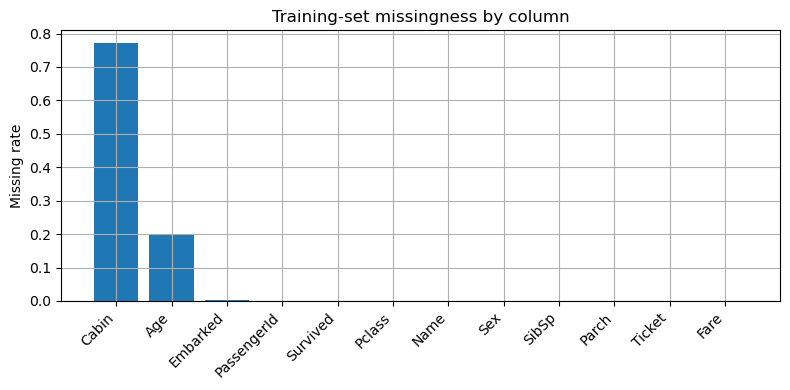

In [7]:
# Step 3B: Missingness bar chart
missing_rate = train_df.isna().mean().sort_values(ascending=False)

plt.figure()
plt.bar(missing_rate.index, missing_rate.values)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Missing rate")
plt.title("Training-set missingness by column")
plt.tight_layout()
plt.show()

### Post-execution interpretation questions

1. Which columns look immediately risky for direct modeling, and why?   
Cabin is risky because it contains a large amount of missing data. Name and Ticket also need careful consideration because they contain many unique values and may not be useful in their raw form.

2. Why is high missingness not always a reason to drop a column immediately?    
Missingness itself can contain useful information. For example, whether a passenger had a recorded cabin may be related to passenger class or survival. Instead of automatically dropping the feature, we can create a missingness indicator.

3. Limitation question: what important data-quality issue is not captured by `isna().sum()` alone?  
isna().sum() does not identify incorrect values that are technically present. For example, a negative age or an incorrectly entered fare would not be counted as missing.


4. **Think like an ML Systems engineer:** what schema checks would you automate before every training run?  
I would check that required columns exist, data types are correct, the target is present, missingness is within an expected range, categorical values are valid, numeric ranges are reasonable, and duplicate rates have not changed unexpectedly.

### Step 4 — Descriptive Statistics, Skewness, and Univariate Visualization

### Pre-coding questions

1. Which numeric feature do you expect to be most positively skewed: `Fare`, `Age`, or `SibSp`? Justify your prediction.    
I expect Fare to be the most positively skewed. Most passengers paid relatively low fares, while a smaller number of passengers paid very high fares.

2. Why can the mean and median tell different stories in skewed data?   
Extreme values can pull the mean toward them. The median is less affected by extreme values, so it can provide a better representation of the typical observation in a highly skewed distribution.

3. What would happen to a histogram if a small number of extreme fares stretch the x-axis?  
Most of the observations would become compressed into a smaller portion of the histogram, making it harder to see the detailed distribution of typical fares.

### Function/class selection and parameter exploration

Use:

- `DataFrame.describe`
- `Series.skew`
- `Series.kurt`
- `matplotlib.pyplot.hist`
- `matplotlib.pyplot.boxplot`

Explore with `help()` or notebook `?`:

- `Series.skew(skipna=True)`
- `Series.kurt(skipna=True)`
- `plt.hist(bins=..., edgecolor=...)`

Explain the effect of:

- `bins` on distribution visibility
- `skipna` on robust summary computation
- boxplot whiskers on apparent outlier counts

In [8]:
# Step 4A: Descriptive statistics for selected numerical features
numeric_cols = ["Age", "Fare", "SibSp", "Parch", "Pclass"]
display(train_df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,714.000,29.699,14.526,0.420,20.125,28.000,38.000,80.000
Fare,891.000,32.204,49.693,0.000,7.910,14.454,31.000,512.329
SibSp,891.000,0.523,1.103,0.000,0.000,0.000,1.000,8.000
Parch,891.000,0.382,0.806,0.000,0.000,0.000,0.000,6.000
Pclass,891.000,2.309,0.836,1.000,2.000,3.000,3.000,3.000


In [9]:
shape_stats = pd.DataFrame({
    "skewness": train_df[numeric_cols].skew(),
    "kurtosis": train_df[numeric_cols].kurt()
})
shape_stats = shape_stats.reindex(shape_stats["skewness"].abs().sort_values(ascending=False).index)
display(shape_stats)

,skewness,kurtosis
Fare,4.787,33.398
SibSp,3.695,17.880
Parch,2.749,9.778
Pclass,-0.631,-1.280
Age,0.389,0.178


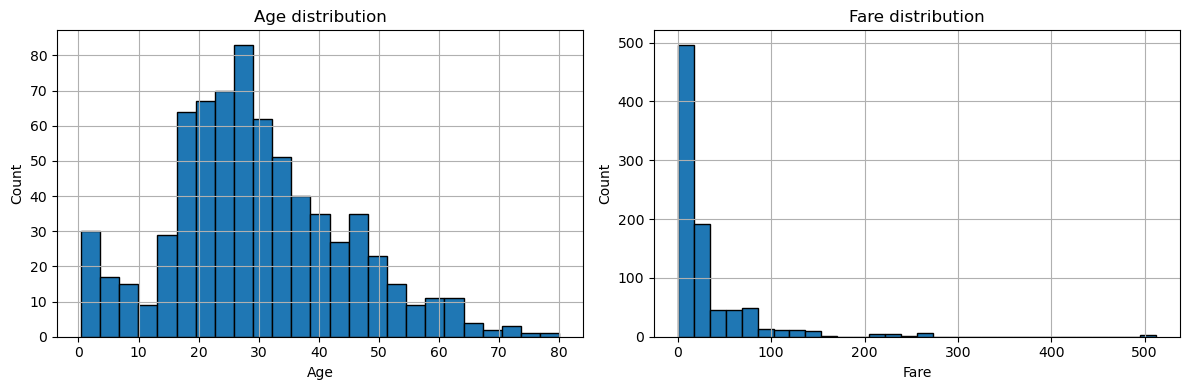

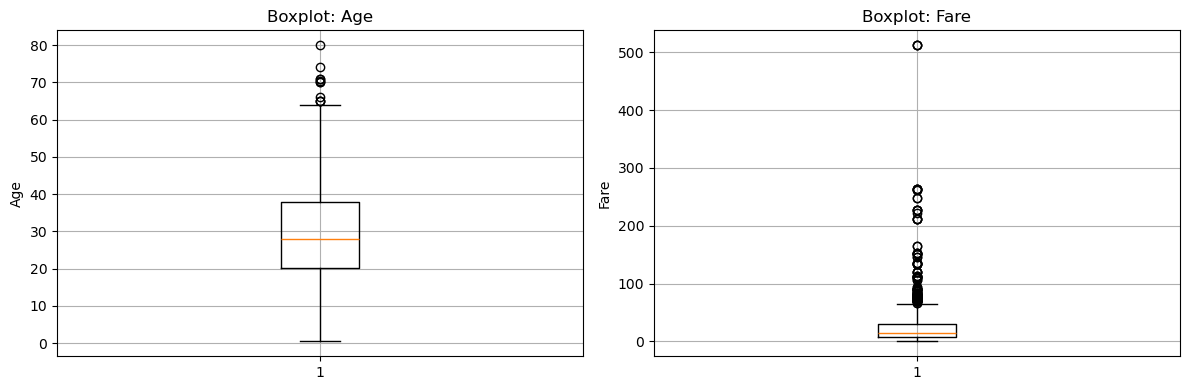

In [10]:
# Step 4B: Histograms and boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df["Age"].dropna(), bins=25, edgecolor="black")
axes[0].set_title("Age distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")

axes[1].hist(train_df["Fare"].dropna(), bins=30, edgecolor="black")
axes[1].set_title("Fare distribution")
axes[1].set_xlabel("Fare")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(train_df["Age"].dropna(), vert=True)
axes[0].set_title("Boxplot: Age")
axes[0].set_ylabel("Age")

axes[1].boxplot(train_df["Fare"].dropna(), vert=True)
axes[1].set_title("Boxplot: Fare")
axes[1].set_ylabel("Fare")
plt.tight_layout()
plt.show()

### Post-execution interpretation questions

1. Which feature appears most non-normal, and what evidence supports that conclusion?   
Fare appears the most non-normal. Its histogram is strongly right-skewed and its boxplot shows several high-value observations. Its skewness is also much larger than that of the other numerical variables.

2. Why might a log transformation be more reasonable for `Fare` than for `Pclass`?  
Fare is a continuous numerical variable with a strong right skew, so log1p can reduce the influence of very large values. Pclass represents passenger classes and is an ordinal categorical-like variable, so taking its logarithm would not have a useful interpretation.

3. Limitation question: why are skewness and kurtosis alone not enough to understand a variable?    
They summarize the shape of a distribution but do not show the actual values, missingness patterns, subgroups, or unusual observations. Histograms, boxplots, and other visualizations are needed to understand the variable more completely.

 
4. **Think like an ML Systems engineer:** 
   - How could a highly skewed feature increase instability across model retraining cycles?  
   A few extreme values can have a large effect on the model. If those observations change between training datasets, the model coefficients can change significantly. Transforming or scaling the feature can make the model more stable.

### Step 5 — Survival-Aware Visualization and Association Analysis

### Pre-coding questions

1. Which relationship do you expect to be stronger: `Survived` with `Sex` or `Survived` with `Embarked`? Why?   
I expect Sex to have a stronger relationship with survival. Historically, women and children were given priority during evacuation, so survival rates differed substantially between male and female passengers.

2. Why can group averages hide important subgroup differences?  
An overall group average can combine very different subgroups. For example, survival may depend on both sex and passenger class, so looking only at the overall survival rate for a group can hide those differences.

3. What would a correlation matrix miss when one variable is categorical?   
A standard correlation matrix focuses on numerical relationships. It cannot directly represent all of the information in nominal categories such as Sex or Embarked.

### Function/class selection and parameter exploration

Use:

- `pandas.crosstab`
- `DataFrame.groupby`
- `matplotlib.pyplot.bar`
- `matplotlib.pyplot.scatter`
- `scipy.stats.chi2_contingency`

Explore with `help()` or notebook `?`:

- `pd.crosstab(index, columns, normalize=None)`
- `chi2_contingency(observed, correction=True)`

Explain the effect of:

- `normalize` in crosstabs
- groupby aggregation choices on interpretation
- continuity correction in chi-square testing

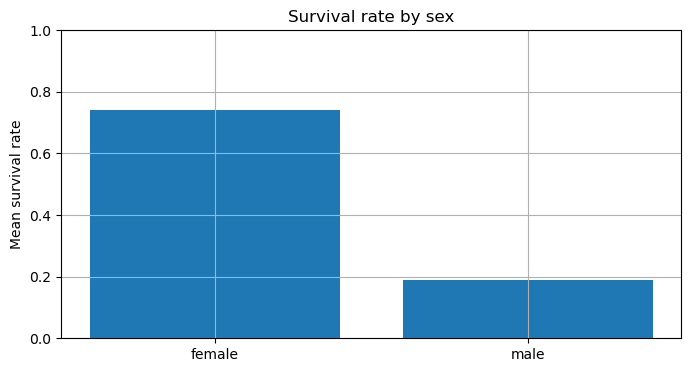

In [11]:
# Step 5A: Survival rate by sex
survival_by_sex = train_df.groupby("Sex")["Survived"].mean().sort_values(ascending=False)

plt.figure()
plt.bar(survival_by_sex.index, survival_by_sex.values)
plt.title("Survival rate by sex")
plt.ylabel("Mean survival rate")
plt.ylim(0, 1)
plt.show()

In [12]:
survival_by_class_sex = (
    train_df
    .groupby(["Pclass", "Sex"], as_index=False)["Survived"]
    .mean()
    .sort_values(["Pclass", "Survived"], ascending=[True, False])
)
display(survival_by_class_sex)

,Pclass,Sex,Survived
0,1,female,0.968
1,1,male,0.369
2,2,female,0.921
3,2,male,0.157
4,3,female,0.500
5,3,male,0.135


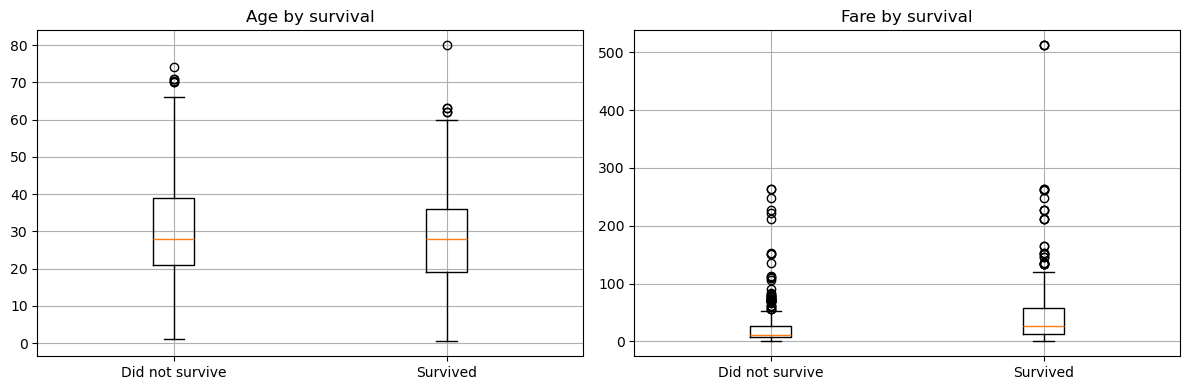

In [13]:
# Step 5B: Age and fare by survival
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(
    [train_df.loc[train_df["Survived"] == 0, "Age"].dropna(),
     train_df.loc[train_df["Survived"] == 1, "Age"].dropna()],
)
axes[0].set_title("Age by survival")
axes[0].set_xticklabels(["Did not survive", "Survived"])

axes[1].boxplot(
    [train_df.loc[train_df["Survived"] == 0, "Fare"].dropna(),
     train_df.loc[train_df["Survived"] == 1, "Fare"].dropna()],
)
axes[1].set_title("Fare by survival")
axes[1].set_xticklabels(["Did not survive", "Survived"])

plt.tight_layout()
plt.show()

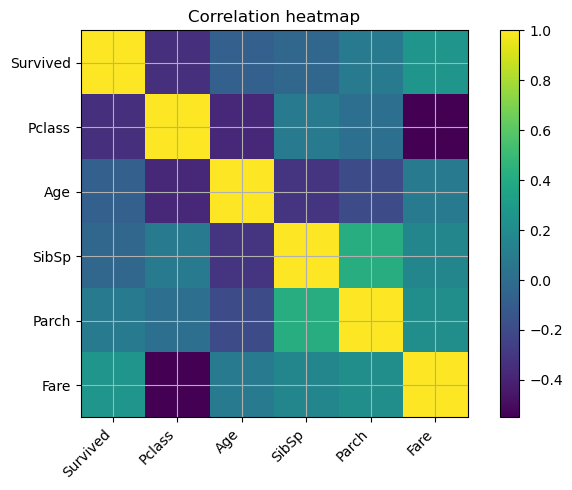

Chi-square statistic: 102.889
p-value: 0.0
Degrees of freedom: 2


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [14]:
# Step 5C: Correlation heatmap for numeric columns
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr_matrix = train_df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(7, 5))
plt.imshow(corr_matrix, interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

# Step 5D: Chi-square test for Pclass vs Survived
contingency = pd.crosstab(train_df["Pclass"], train_df["Survived"])
chi2_stat, p_value, dof, expected = chi2_contingency(contingency)
print("Chi-square statistic:", round(chi2_stat, 3))
print("p-value:", round(p_value, 6))
print("Degrees of freedom:", dof)
display(contingency)

### Post-execution interpretation questions

1. Which patterns appear visually strongest for survival prediction?    
Sex and passenger class show some of the strongest relationships with survival. Female passengers generally had much higher survival rates than male passengers, and first-class passengers generally had better survival outcomes than third-class passengers.

2. How should you interpret a very small chi-square p-value in this context?    
A very small p-value suggests that passenger class and survival are statistically associated. It provides evidence that the survival distribution differs across passenger classes.

3. Limitation question: why does a statistically significant association not automatically imply causal interpretation?  
Statistical association does not prove that one variable directly caused the other. Other factors could influence both variables or explain the observed relationship.


4. **Think like an ML Systems engineer:** 
   - What subgroup metrics would you monitor after deployment to ensure reliability across passenger segments?    
I would monitor accuracy, recall, precision, and false-positive and false-negative rates across important groups such as sex and passenger class. I would also monitor whether prediction performance changes over time for these groups.

### Step 6 — Missing Data and Anomaly Detection

### Pre-coding questions

1. Which is more dangerous for downstream modeling: a column with 77% missingness or a column with 1% impossible values? Defend your answer.    
It depends on the situation. A column with 77% missingness may provide limited information, but 1% impossible values can seriously distort a model if they are extreme or represent data-entry errors. The type of problem and how the feature is used should determine the response.

2. Why might the same extreme fare be treated differently in fraud detection versus passenger-survival prediction?  
In fraud detection, an extreme value may be an important signal and should probably be retained or flagged. In the Titanic dataset, an extreme fare may represent a legitimate first-class or group ticket rather than an error, so automatically removing it could discard useful information.

3. What tradeoff arises when removing outliers instead of flagging them?    
Removing outliers can make the data cleaner but may remove legitimate observations. Flagging them preserves the original data while allowing the model or analyst to treat the observations differently.

### Function/class selection and parameter exploration

Use:

- `Series.quantile`
- `numpy.abs`
- `scipy.stats.zscore`
- `DataFrame.duplicated`

Explore with `help()` or notebook `?`:

- `Series.quantile(q)`
- `stats.zscore(a, nan_policy='omit')`

Explain the effect of:

- IQR multiplier choice on sensitivity
- `nan_policy` in z-score calculation
- duplicate-subset definition on data cleaning decisions

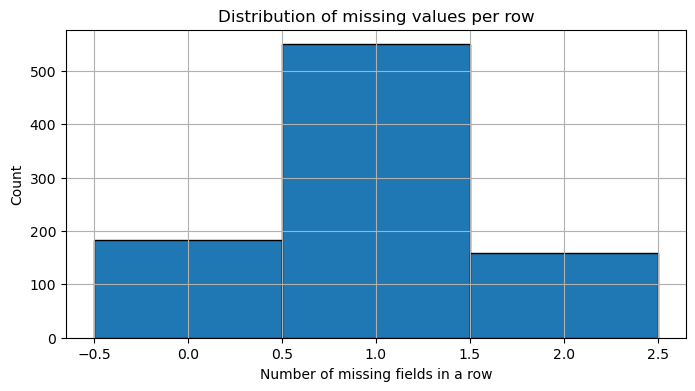

In [15]:
# Step 6A: Missingness pattern by row
row_missing_count = train_df.isna().sum(axis=1)

plt.figure()
plt.hist(row_missing_count, bins=range(row_missing_count.max() + 2), edgecolor="black", align="left")
plt.title("Distribution of missing values per row")
plt.xlabel("Number of missing fields in a row")
plt.ylabel("Count")
plt.show()

In [16]:
fare_q1 = train_df["Fare"].quantile(0.25)
fare_q3 = train_df["Fare"].quantile(0.75)
fare_iqr = fare_q3 - fare_q1

fare_lower_bound = fare_q1 - 1.5 * fare_iqr
fare_upper_bound = fare_q3 + 1.5 * fare_iqr
fare_outlier_mask = (train_df["Fare"] < fare_lower_bound) | (train_df["Fare"] > fare_upper_bound)

print("Fare lower bound:", round(fare_lower_bound, 3))
print("Fare upper bound:", round(fare_upper_bound, 3))
print("Flagged rows:", int(fare_outlier_mask.sum()))

Fare lower bound: -26.724
Fare upper bound: 65.634
Flagged rows: 116


In [17]:
age_z = pd.Series(stats.zscore(train_df["Age"], nan_policy="omit"), index=train_df.index)
age_extreme_mask = age_z.abs() > 3
print("Age extreme rows:", int(age_extreme_mask.fillna(False).sum()))

Age extreme rows: 2


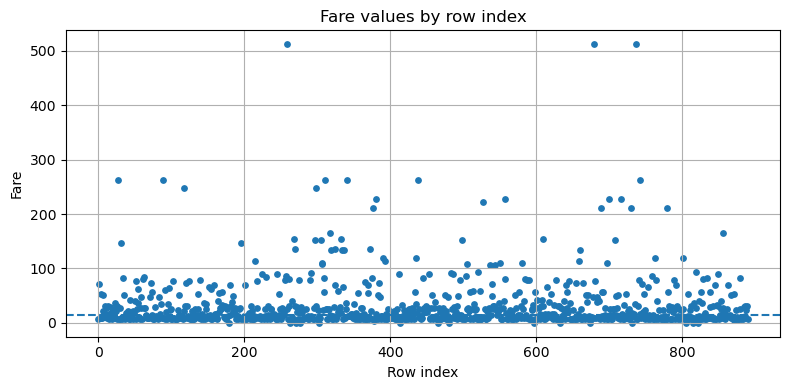

Exact duplicate full names: 0


In [18]:
# Step 6B: Visualize fare anomalies
plt.figure(figsize=(8, 4))
plt.scatter(train_df.index, train_df["Fare"], s=15)
plt.axhline(train_df["Fare"].median(), linestyle="--")
plt.title("Fare values by row index")
plt.xlabel("Row index")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

# Step 6C: Duplicate names (not necessarily true duplicates, but useful for reasoning)
name_duplicate_count = train_df["Name"].duplicated().sum()
print("Exact duplicate full names:", int(name_duplicate_count))

### Post-execution interpretation questions

1. Are the detected fare outliers necessarily errors? Why or why not?   
No, some high fares are legitimate and may represent expensive first-class tickets or group purchases. An IQR rule identifies unusual observations, but it does not prove that they are incorrect.

2. Why might `Cabin` missingness deserve a different treatment from `Age` missingness?  
Age is a numerical variable where median imputation can provide a reasonable estimate. Cabin has much more missingness, and the fact that the cabin is missing may itself contain information. A missingness indicator can therefore be useful.

3. Limitation question: what weakness does the z-score method have when the underlying distribution is skewed?  
Z-scores are based on the mean and standard deviation. A highly skewed distribution can make these statistics less representative of the typical observation, causing the method to incorrectly classify some values as normal or extreme.


4. **Think like an ML Systems engineer:** 
   - Would you drop, cap, or flag fare anomalies in a production preprocessing pipeline for this task?   
I would probably avoid automatically dropping them. I would first determine whether the values are valid. If they are valid, I would retain them and use log1p to reduce their influence. A separate anomaly flag could also be useful.

### Step 7 — Encoding Workshop: Target Label Encoding, Binary Encoding, and One-Hot Encoding

### Pre-coding questions

1. Why is `LabelEncoder` appropriate for the target label but often inappropriate for nominal input features?   
The target is a class label, so converting classes into numeric values is appropriate. For nominal input features, integer values can incorrectly suggest an ordering that does not exist.

2. Why is one-hot encoding usually safer than integer coding for `Embarked` or `Sex`?   
One-hot encoding creates separate binary columns without implying that one category is greater than another. This is more appropriate for nominal categories.

3. What tradeoff does one-hot encoding introduce for memory and feature dimensionality?     
One-hot encoding can create many additional columns, especially for high-cardinality features. This can increase memory usage and model complexity.

### Function/class selection and parameter exploration

Use:

- `sklearn.preprocessing.LabelEncoder`
- `pandas.get_dummies`
- `sklearn.preprocessing.OneHotEncoder`

Explore with `help()` or notebook `?`:

- `LabelEncoder()`
- `pd.get_dummies(data, drop_first=False, dtype=int)`
- `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`

Explain the effect of:

- label encoding on target class representation
- `drop_first` on dummy-column redundancy
- `handle_unknown` on inference robustness
- sparse versus dense output on memory

In [19]:
# Step 7A: Create a string version of the target to motivate label encoding
eda_df = train_df.copy()
eda_df["SurvivedLabel"] = eda_df["Survived"].map({0: "died", 1: "survived"})

display(eda_df[["Survived", "SurvivedLabel"]].head())

,Survived,SurvivedLabel
0,0,died
1,1,survived
2,1,survived
3,1,survived
4,0,died


In [20]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(eda_df["SurvivedLabel"])
print("Classes:", label_encoder.classes_)
print("First 10 encoded values:", y_encoded[:10])

Classes: ['died' 'survived']
First 10 encoded values: [0 1 1 1 0 0 0 0 1 1]


In [21]:
# Step 7B: Binary / numerical encoding for a binary feature
eda_df["SexBinary"] = eda_df["Sex"].map({"male": 0, "female": 1})
display(eda_df[["Sex", "SexBinary"]].head())

,Sex,SexBinary
0,male,0
1,female,1
2,female,1
3,female,1
4,male,0


In [22]:
nominal_ohe = pd.get_dummies(
    eda_df[["Sex", "Embarked"]],
    dummy_na=True,
    drop_first=False,
    dtype=int
)
display(nominal_ohe.head())

,Sex_female,Sex_male,Sex_nan,Embarked_C,Embarked_Q,Embarked_S,Embarked_nan
0,0,1,0,0,0,1,0
1,1,0,0,1,0,0,0
2,1,0,0,0,0,1,0
3,1,0,0,0,0,1,0
4,0,1,0,0,0,1,0


In [23]:
encoding_comparison = pd.DataFrame([
    {
        "original_feature": "SurvivedLabel",
        "encoded_strategy": "LabelEncoder",
        "why_it_is_or_is_not_appropriate": "Appropriate because it is the target label y and many estimators expect numeric targets."
    },
    {
        "original_feature": "Sex",
        "encoded_strategy": "Binary mapping",
        "why_it_is_or_is_not_appropriate": "Appropriate here because the feature is binary and the mapping is easy to interpret."
    },
    {
        "original_feature": "Embarked",
        "encoded_strategy": "One-hot encoding",
        "why_it_is_or_is_not_appropriate": "Appropriate because Embarked is nominal and should not imply order."
    },
    {
        "original_feature": "Embarked",
        "encoded_strategy": "Ordinal / integer coding",
        "why_it_is_or_is_not_appropriate": "Risky because integer codes create an artificial ranking among ports."
    }
])
display(encoding_comparison)

,original_feature,encoded_strategy,why_it_is_or_is_not_appropriate
0,SurvivedLabel,LabelEncoder,Appropriate because it is the target label y a...
1,Sex,Binary mapping,Appropriate here because the feature is binary...
2,Embarked,One-hot encoding,Appropriate because Embarked is nominal and sh...
3,Embarked,Ordinal / integer coding,Risky because integer codes create an artifici...


### Post-execution interpretation questions

1. Why is the phrase “label encoding” easy to misuse in beginner discussions of feature preprocessing?  
People sometimes use “label encoding” to describe converting any categorical feature into numbers. However, LabelEncoder is intended for target labels, while categorical input features often need one-hot encoding or another appropriate categorical transformation.

2. In this dataset, when is binary mapping preferable to one-hot encoding, and when is it not?  
Binary mapping is simple and appropriate for Sex because it has only two categories. For Embarked, one-hot encoding is better because it has multiple nominal categories and there is no natural numerical ordering.

3. Limitation question: what problem can arise when one-hot encoding a feature with hundreds of rare categories?    
It can create hundreds of columns with very few observations in each category. This increases memory usage and can cause overfitting.  


4. **Think like an ML Systems engineer:** 
   - Why is `handle_unknown='ignore'` important for stable inference services?   
   It prevents the model from failing when new categorical values appear in production. Instead of producing an error, the encoder ignores the unknown category and continues making a prediction.

### Step 8 — Numerical Transformation, Scaling, and Leakage-Safe Preprocessing

### Pre-coding questions

1. Why should `Fare` transformation and imputation be learned from the training split only?     
The preprocessing should not use information from the test set. If statistics such as the median are calculated using the entire dataset, information from the test data can leak into the training process and make evaluation overly optimistic.

2. Why might standardization matter for logistic regression even though the model is linear?    
Features with very different scales can make optimization more difficult. Standardization puts numerical features on a more comparable scale and can help the logistic regression solver converge more efficiently.

3. What failure mode appears if preprocessing is performed on the full dataset before splitting?    
Data leakage can occur. The test set indirectly influences preprocessing parameters such as imputation values, scaling statistics, or encoding information.

### Function/class selection and parameter exploration

Use:

- `numpy.log1p`
- `SimpleImputer`
- `StandardScaler`
- `ColumnTransformer`
- `Pipeline`

Explore with `help()` or notebook `?`:

- `SimpleImputer(strategy='median')`
- `StandardScaler(with_mean=True, with_std=True)`
- `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`
- `ColumnTransformer(transformers=..., remainder='drop')`

Explain the effect of:

- median vs most-frequent imputation
- scaling on optimization and coefficient comparability
- `remainder` in `ColumnTransformer`
- dense vs sparse encoded output

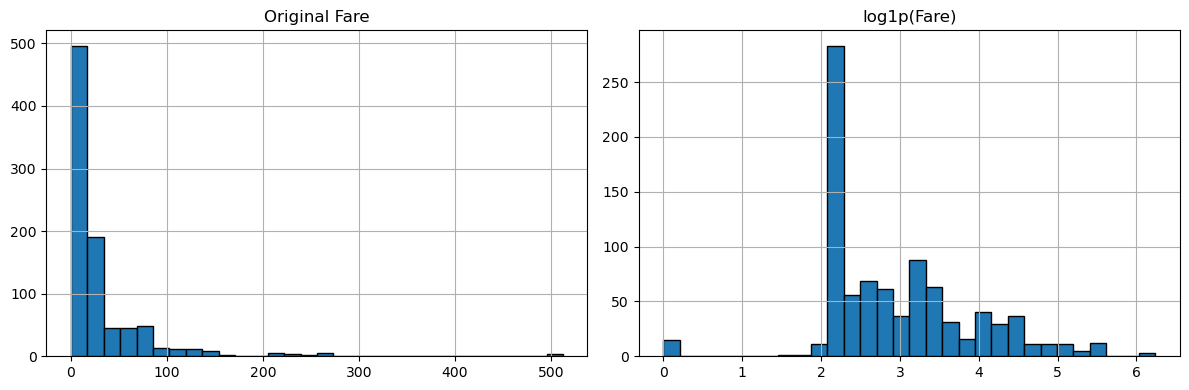

In [24]:
# Step 8A: Feature engineering helpers
model_df = train_df.copy()
model_df["FareLog1p"] = np.log1p(model_df["Fare"])
model_df["IsCabinMissing"] = model_df["Cabin"].isna().astype(int)
model_df["FamilySize"] = model_df["SibSp"] + model_df["Parch"] + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(model_df["Fare"].dropna(), bins=30, edgecolor="black")
axes[0].set_title("Original Fare")

axes[1].hist(model_df["FareLog1p"].dropna(), bins=30, edgecolor="black")
axes[1].set_title("log1p(Fare)")
plt.tight_layout()
plt.show()

In [25]:
numeric_features = ['Age', 'FareLog1p', 'SibSp', 'Parch', 'FamilySize', 'Pclass', 'IsCabinMissing']
categorical_features = ['Sex', 'Embarked']

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Age', 'FareLog1p', 'SibSp', 'Parch', 'FamilySize', 'Pclass', 'IsCabinMissing']
Categorical features: ['Sex', 'Embarked']


In [26]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'FareLog1p', 'SibSp', 'Parch',
                                  'FamilySize', 'Pclass', 'IsCabinMissing']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['Sex', 'Embarked'])])


### Post-execution interpretation questions

1. Why is `FareLog1p` a feature transformation rather than a new source of information?       
FareLog1p is calculated directly from the original Fare value. It does not introduce outside information. It simply changes the representation of the existing information to reduce skewness.

2. Why is `IsCabinMissing` potentially useful even if `Cabin` itself is mostly missing?     
Missingness may have a relationship with passenger class or survival. A binary indicator allows the model to use that information without trying to impute the actual cabin number.

3. Limitation question: what information is still lost when raw `Cabin` strings are reduced to a missingness flag only?     
The model loses information about the actual cabin location, deck, and cabin grouping. These could potentially provide useful information about a passenger's location and class.

4. **Think like an ML Systems engineer:** why are `Pipeline` and `ColumnTransformer` preferable to ad hoc notebook-side preprocessing?      
They make preprocessing reproducible and consistent between training and inference. They also help prevent leakage because preprocessing steps are fitted only on the training data when the pipeline is trained.

### Step 9 — Baseline Model

### Pre-coding questions

1. Why is a simple baseline valuable before building a more complex preprocessing pipeline?     
A baseline provides a reference point. We can determine whether the additional preprocessing and features actually improve the model rather than assuming that a more complicated model is automatically better.

2. Which bias might a numeric-only baseline introduce for this dataset?     
A numeric-only model ignores important categorical information such as Sex and Embarked. This can cause the model to miss strong relationships with survival.

3. Why should the evaluation split be stratified for Titanic survival prediction?   
Stratification keeps approximately the same proportion of survivors and non-survivors in both the training and testing sets. This makes the evaluation more representative.

### Function/class selection and parameter exploration

Use:

- `train_test_split`
- `SimpleImputer`
- `LogisticRegression`

Explore with `help()` or notebook `?`:

- `LogisticRegression(C=1.0, max_iter=1000, solver='lbfgs')`

Explain the effect of:

- `stratify` on class balance
- `C` on regularization strength
- `max_iter` on solver convergence
- choice of a minimal baseline feature set on bias and interpretability

In [27]:
# Step 9A: Baseline model using only a small numeric subset
baseline_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

X = model_df.drop(columns=["SurvivedLabel"], errors="ignore")
y = model_df["Survived"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train_base = X_train[baseline_features].copy()
X_test_base = X_test[baseline_features].copy()

baseline_imputer = SimpleImputer(strategy="median")
X_train_base_imp = baseline_imputer.fit_transform(X_train_base)
X_test_base_imp = baseline_imputer.transform(X_test_base)

baseline_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline_model.fit(X_train_base_imp, y_train)

baseline_pred = baseline_model.predict(X_test_base_imp)
baseline_proba = baseline_model.predict_proba(X_test_base_imp)[:, 1]

baseline_results = {
    "accuracy": accuracy_score(y_test, baseline_pred),
    "roc_auc": roc_auc_score(y_test, baseline_proba)
}
baseline_results

{'accuracy': 0.6636771300448431, 'roc_auc': 0.6840095060261416}

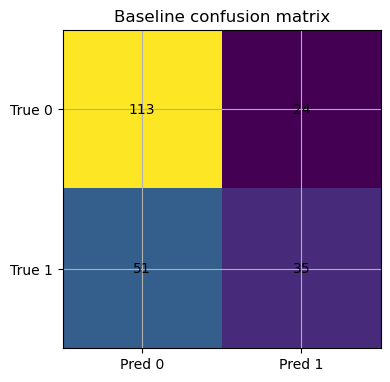

              precision    recall  f1-score   support

           0       0.69      0.82      0.75       137
           1       0.59      0.41      0.48        86

    accuracy                           0.66       223
   macro avg       0.64      0.62      0.62       223
weighted avg       0.65      0.66      0.65       223



In [28]:
# Step 9B: Baseline confusion matrix
baseline_cm = confusion_matrix(y_test, baseline_pred)

plt.figure(figsize=(4, 4))
plt.imshow(baseline_cm, interpolation="nearest")
plt.title("Baseline confusion matrix")
plt.xticks([0, 1], ["Pred 0", "Pred 1"])
plt.yticks([0, 1], ["True 0", "True 1"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, baseline_cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

print(classification_report(y_test, baseline_pred))

### Post-execution interpretation questions

1. What kinds of information can this baseline capture well, and what is it likely missing?     
The baseline can capture relationships involving passenger class, age, family-related variables, and fare. It is missing important categorical information such as sex and embarkation port.

2. Which metric is more informative here: accuracy or ROC AUC, and why?     
ROC AUC is useful because it evaluates how well the model separates the two classes across different classification thresholds. Accuracy is still useful, but it only evaluates the predictions at one threshold.

3. Limitation question: why should we be cautious about over-interpreting a single random split?    
A single split can produce a result that depends on which observations happened to be placed in the test set. Cross-validation would provide a better estimate of how consistently the model performs.

  
4. **Think like an ML Systems engineer:** 
   - What latency advantages does this simple baseline have?   
The baseline uses only a few numerical features and simple median imputation. It requires fewer preprocessing operations and fewer features, so it should be fast to train and predict.

### Step 10 — Improved Leakage-Safe Model, Diagnostics, and Systems Discussion

### Pre-coding questions

1. Which feature-processing choices in the improved model are most likely to outperform the baseline, and why?  
Adding Sex, Embarked, FamilySize, FareLog1p, and IsCabinMissing should improve the model because these features provide information that the numeric-only baseline does not use. Scaling and appropriate categorical encoding also make the features easier for logistic regression to use.

2. Why might an improved model still fail in production even if its notebook metrics are higher?    
The production data could change over time. There could be data drift, missing values, new categories, incorrect inputs, or changes in the relationship between features and the target. A good test score does not guarantee reliable production performance.

3. Which tradeoff matters more for this use case: interpretability, throughput, or raw leaderboard score? Justify your answer.  
Interpretability is important because logistic regression makes it easier to understand how different features relate to predictions. Throughput is also useful, but Titanic is a relatively small dataset, so prediction speed is unlikely to be the main concern.

### Function/class selection and parameter exploration

Use:

- `Pipeline`
- `ColumnTransformer`
- `LogisticRegression`
- `classification_report`

Explore with `help()` or notebook `?`:

- `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`
- `Pipeline(steps=...)`
- `LogisticRegression(C=..., class_weight=None, max_iter=...)`

Explain the effect of:

- `handle_unknown` on production robustness
- `C` on coefficient shrinkage
- `class_weight` on imbalance handling
- dense transformed matrices on memory cost

In [29]:
# Step 10A: Improved model
improved_model = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

improved_model.fit(X_train, y_train)

improved_pred = improved_model.predict(X_test)
improved_proba = improved_model.predict_proba(X_test)[:, 1]

improved_results = {
    "accuracy": accuracy_score(y_test, improved_pred),
    "roc_auc": roc_auc_score(y_test, improved_proba)
}

comparison_df = pd.DataFrame([
    {"model": "Baseline numeric-only", **baseline_results},
    {"model": "Improved pipeline", **improved_results}
])
display(comparison_df)

,model,accuracy,roc_auc
0,Baseline numeric-only,0.664,0.684
1,Improved pipeline,0.794,0.837


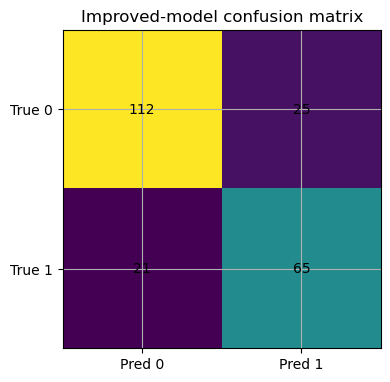

              precision    recall  f1-score   support

           0       0.84      0.82      0.83       137
           1       0.72      0.76      0.74        86

    accuracy                           0.79       223
   macro avg       0.78      0.79      0.78       223
weighted avg       0.80      0.79      0.79       223



In [30]:
# Step 10B: Improved-model confusion matrix
improved_cm = confusion_matrix(y_test, improved_pred)

plt.figure(figsize=(4, 4))
plt.imshow(improved_cm, interpolation="nearest")
plt.title("Improved-model confusion matrix")
plt.xticks([0, 1], ["Pred 0", "Pred 1"])
plt.yticks([0, 1], ["True 0", "True 1"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, improved_cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

print(classification_report(y_test, improved_pred))

,feature,coefficient,abs_coefficient
8,cat__Sex_male,-1.308,1.308
7,cat__Sex_female,1.278,1.278
0,num__Age,-0.556,0.556
5,num__Pclass,-0.519,0.519
6,num__IsCabinMissing,-0.398,0.398
1,num__FareLog1p,0.348,0.348
10,cat__Embarked_Q,0.289,0.289
11,cat__Embarked_S,-0.284,0.284
2,num__SibSp,-0.230,0.230
4,num__FamilySize,-0.162,0.162


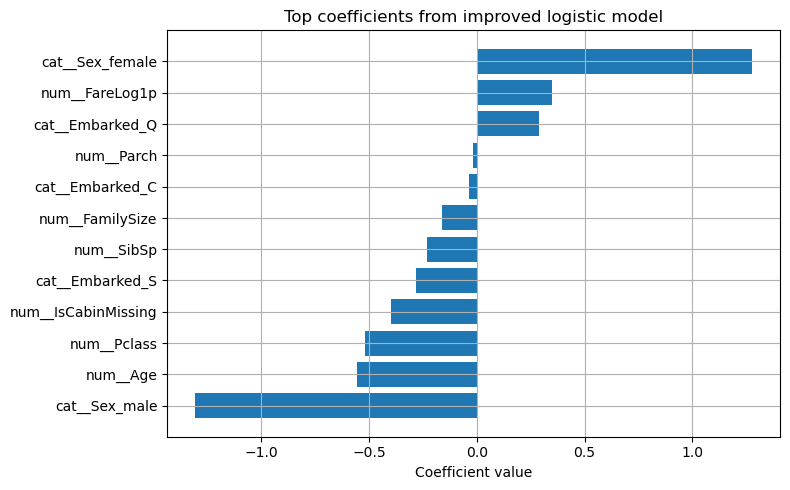

In [31]:
# Step 10C: Inspect interpretable coefficients from the improved pipeline
feature_names = improved_model.named_steps["preprocessor"].get_feature_names_out()
coefs = improved_model.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs,
    "abs_coefficient": np.abs(coefs)
}).sort_values("abs_coefficient", ascending=False)

display(coef_df.head(12))

top_plot = coef_df.head(12).sort_values("coefficient")
plt.figure(figsize=(8, 5))
plt.barh(top_plot["feature"], top_plot["coefficient"])
plt.title("Top coefficients from improved logistic model")
plt.xlabel("Coefficient value")
plt.tight_layout()
plt.show()

### Post-execution interpretation questions

1. Which preprocessing choices most plausibly explain the difference between the baseline and improved model?   
The improved model uses categorical features such as Sex and Embarked, along with FamilySize, FareLog1p, and the cabin-missing indicator. It also imputes and scales numerical features and one-hot encodes categorical features. These choices give the model more useful information than the baseline.

2. Why should coefficient magnitude be interpreted carefully after one-hot encoding and scaling?    
Numerical features have been standardized while categorical features are represented by separate binary columns. Therefore, coefficient sizes do not always have a direct apples-to-apples interpretation across every feature.

3. Limitation question: what additional validation step would strengthen confidence beyond one split?   
Cross-validation would strengthen confidence because the model would be evaluated on multiple different train/validation splits. This would show whether the model performs consistently rather than relying on one particular split.


4. **Think like an ML Systems engineer:** 
   - What would you log in production to detect drift, leakage, or performance regression?   
I would log feature distributions, missingness rates, categorical frequencies, prediction distributions, model confidence, and data quality checks. When actual labels become available, I would also monitor accuracy, precision, recall, ROC AUC, and subgroup performance over time.

##  Reflection

1. Which EDA step most changed your understanding of the Titanic data, and why?     
The survival visualizations changed my understanding the most because they showed how strongly survival was related to sex and passenger class. The plots made these differences easier to see than the raw dataset alone.

2. Which transformation or encoding choice would you defend most strongly in a code review?     
I would strongly defend using one-hot encoding for nominal categorical variables such as Embarked. It avoids creating an artificial numerical ranking between the different ports. I would also defend using handle_unknown="ignore" because it makes the model safer during inference.

3. Which remaining limitation would you investigate next: fairness across groups, calibration, cross-validation stability, or richer text/cabin feature engineering?    
I would investigate cross-validation stability next. A single train/test split can give an unreliable estimate of performance, so cross-validation would help determine whether the improved model consistently performs better.

4. How would you convert this notebook into a batch inference pipeline that is reproducible and monitorable?    
I would save the complete preprocessing and model as one scikit-learn pipeline. The batch system would validate the incoming schema, apply the same preprocessing steps, generate predictions, and save the results. I would also log the model version, input data statistics, prediction statistics, processing time, and data-quality checks. Performance could be monitored over time once actual outcomes become available.

**End of Lab**